# Maternal Health Risk Prediction — Model Comparison & Hyperparameter Tuning

**Objective:** Build a machine learning workflow that predicts a pregnant patient's **risk level**
(`low risk`, `mid risk`, `high risk`) from basic health measurements.

**Dataset:** `Maternal Health Risk Data Set.csv` — 1,014 records with 6 features:

| Feature | Description |
|---|---|
| `Age` | Age of the patient (years) |
| `SystolicBP` | Upper blood pressure (mmHg) |
| `DiastolicBP` | Lower blood pressure (mmHg) |
| `BS` | Blood sugar (mmol/L) |
| `BodyTemp` | Body temperature (°F) |
| `HeartRate` | Resting heart rate (bpm) |
| `RiskLevel` | **Target** — low / mid / high risk |

**Workflow:**
1. Load and explore the data (EDA)
2. Preprocess — encode the target, split, and scale
3. Train **four** classifiers: Decision Tree, Gradient Boosting, XGBoost, and SVC
4. Compare their performance and select the **best** model
5. Retrain the best model with **GridSearchCV** hyperparameter tuning
6. Save the final model with **joblib** and demonstrate loading it for prediction

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & model selection
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder

# The four models we will compare
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)

# Model persistence
import joblib

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Load and Inspect the Data

In [2]:
df = pd.read_csv('Maternal Health Risk Data Set.csv')
print(f'Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns')
df.head()

Dataset shape: 1014 rows x 7 columns


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


In [4]:
df.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,29.871795,113.198225,76.460552,8.725986,98.665089,74.301775
std,13.474386,18.403913,13.885796,3.293532,1.371384,8.088702
min,10.000000,70.000000,49.000000,6.000000,98.000000,7.000000
25%,19.000000,100.000000,65.000000,6.900000,98.000000,70.000000
50%,26.000000,120.000000,80.000000,7.500000,98.000000,76.000000
75%,39.000000,120.000000,90.000000,8.000000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


### Data Quality Checks

We check for **missing values** and **duplicate rows**. Duplicates are important to remove:
if the same record appears in both the training and test set, the model gets an unfair
"sneak peek" at the test data (**data leakage**), which inflates the test score.

In [5]:
print('Missing values per column:')
print(df.isnull().sum())

n_duplicates = df.duplicated().sum()
print(f'\nDuplicate rows found: {n_duplicates}')

df = df.drop_duplicates().reset_index(drop=True)
print(f'Shape after removing duplicates: {df.shape}')

Missing values per column:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

Duplicate rows found: 562
Shape after removing duplicates: (452, 7)


## 3. Exploratory Data Analysis (EDA)

### 3.1 Target Class Distribution
First we check whether the classes are balanced — an imbalanced target would influence
which metric we trust and whether we need stratified splitting.

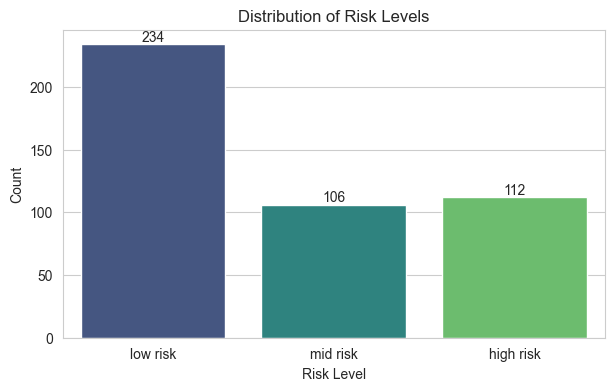

RiskLevel
low risk     0.518
high risk    0.248
mid risk     0.235
Name: proportion, dtype: float64


In [6]:
plt.figure(figsize=(7, 4))
order = ['low risk', 'mid risk', 'high risk']
ax = sns.countplot(data=df, x='RiskLevel', order=order, palette='viridis')
for container in ax.containers:
    ax.bar_label(container)
plt.title('Distribution of Risk Levels')
plt.xlabel('Risk Level')
plt.ylabel('Count')
plt.show()

print(df['RiskLevel'].value_counts(normalize=True).round(3))

### 3.2 Feature Correlations
The heatmap shows how strongly the numeric features are related to each other.

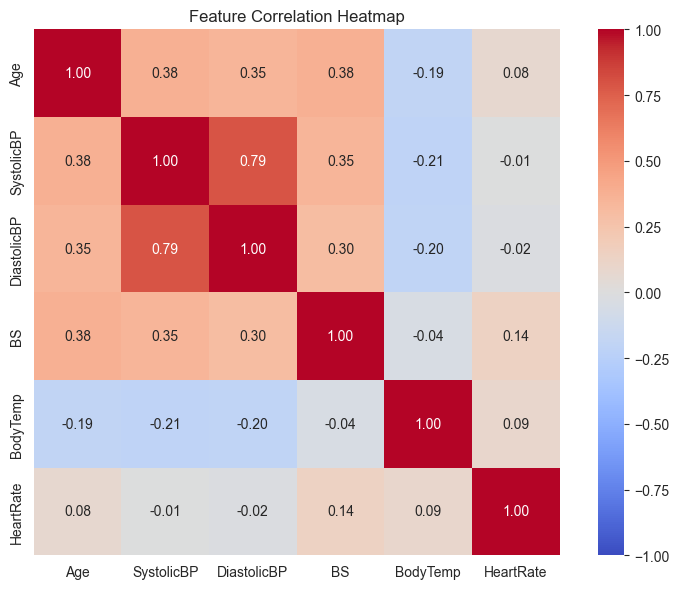

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns='RiskLevel').corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

### 3.3 Feature Distributions by Risk Level
Boxplots reveal which features separate the risk classes. Notice how **blood sugar (BS)**
and **systolic blood pressure** shift upward for high-risk patients.

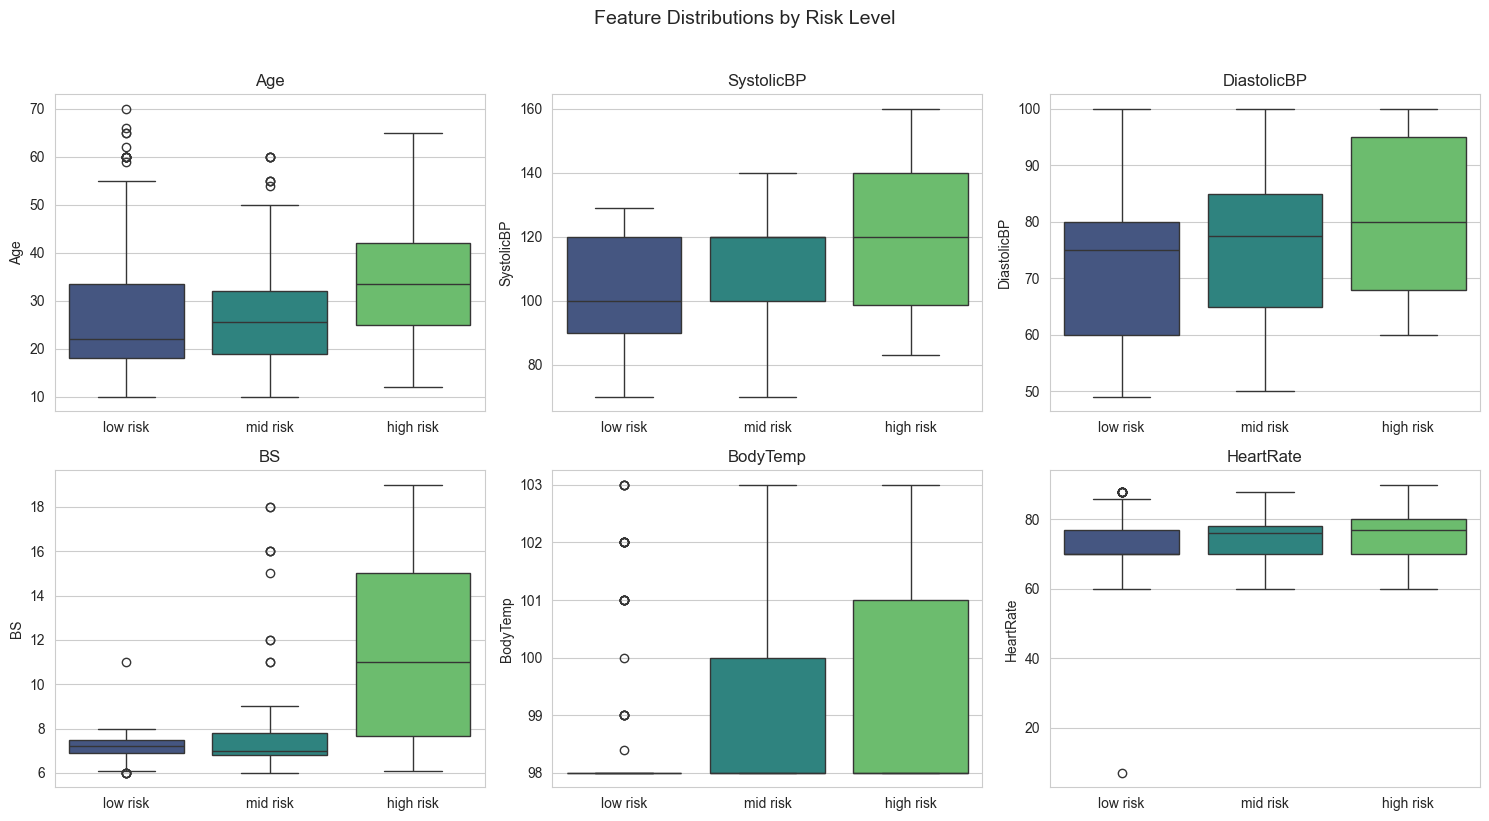

In [8]:
features = ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x='RiskLevel', y=col, order=order, palette='viridis', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Feature Distributions by Risk Level', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## 4. Preprocessing

Three steps:
1. **Encode the target** :— models (especially XGBoost) need numeric class labels, so we map
   the text labels to integers with `LabelEncoder`.
2. **Train/test split** :— 80/20, **stratified** so each split keeps the same class proportions.
3. **Feature scaling** :— `StandardScaler` puts all features on the same scale. This is
   *essential* for SVC (a distance-based model). Tree-based models don't need it, but scaling
   does not harm them, so we use the scaled data for all four models for a fair comparison.

> ⚠️ The scaler is fitted **only on the training set** and then applied to the test set ; fitting
> it on all the data would leak test-set information into training.

In [9]:
# 1. Encode the target labels
le = LabelEncoder()
df['RiskLevel_encoded'] = le.fit_transform(df['RiskLevel'])
print('Label mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

X = df[features]
y = df['RiskLevel_encoded']

Label mapping: {'high risk': np.int64(0), 'low risk': np.int64(1), 'mid risk': np.int64(2)}


In [10]:
# 2. Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set:     {X_test.shape[0]} samples')

Training set: 361 samples
Test set:     91 samples


In [11]:
# 3. Scale the features (fit on train only!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=features).describe().loc[['mean', 'std']].round(2)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
mean,-0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Train and Evaluate Four Models

We train each model with its **default hyperparameters** first, to get a fair baseline
comparison. The models:

| Model | Type | Key idea |
|---|---|---|
| **Decision Tree** | Single tree | Splits data with if/else rules |
| **Gradient Boosting** | Ensemble (sklearn) | Trees built sequentially, each correcting the previous errors |
| **XGBoost** | Ensemble (optimized) | Regularized, high-performance gradient boosting |
| **SVC** | Kernel method | Finds the maximum-margin decision boundary |

In [12]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='mlogloss'),
    'SVC': SVC(random_state=RANDOM_STATE),
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    results[name] = {'Accuracy': acc, 'F1 (macro)': f1_macro,
                     'F1 (weighted)': f1_weighted}
    predictions[name] = y_pred
    print(f'{name:<20} Accuracy: {acc:.4f} | Macro F1: {f1_macro:.4f} | '
          f'Weighted F1: {f1_weighted:.4f}')

Decision Tree        Accuracy: 0.5824 | Macro F1: 0.5721 | Weighted F1: 0.5937


Gradient Boosting    Accuracy: 0.6484 | Macro F1: 0.6091 | Weighted F1: 0.6426


XGBoost              Accuracy: 0.5824 | Macro F1: 0.5554 | Weighted F1: 0.5882
SVC                  Accuracy: 0.6703 | Macro F1: 0.5654 | Weighted F1: 0.6305


### 5.1 Detailed Classification Reports
Per-class precision, recall and F1 for each model — this shows *which classes* each
model struggles with (typically `mid risk` is the hardest to separate).

In [13]:
for name, y_pred in predictions.items():
    print(f'{"=" * 55}\n{name}\n{"=" * 55}')
    print(classification_report(y_test, y_pred, target_names=le.classes_))

Decision Tree
              precision    recall  f1-score   support

   high risk       0.89      0.70      0.78        23
    low risk       0.62      0.64      0.63        47
    mid risk       0.28      0.33      0.30        21

    accuracy                           0.58        91
   macro avg       0.60      0.56      0.57        91
weighted avg       0.61      0.58      0.59        91

Gradient Boosting
              precision    recall  f1-score   support

   high risk       0.94      0.70      0.80        23
    low risk       0.65      0.79      0.71        47
    mid risk       0.35      0.29      0.32        21

    accuracy                           0.65        91
   macro avg       0.65      0.59      0.61        91
weighted avg       0.65      0.65      0.64        91

XGBoost
              precision    recall  f1-score   support

   high risk       0.89      0.70      0.78        23
    low risk       0.63      0.68      0.65        47
    mid risk       0.23      0.24  

### 5.2 Confusion Matrices

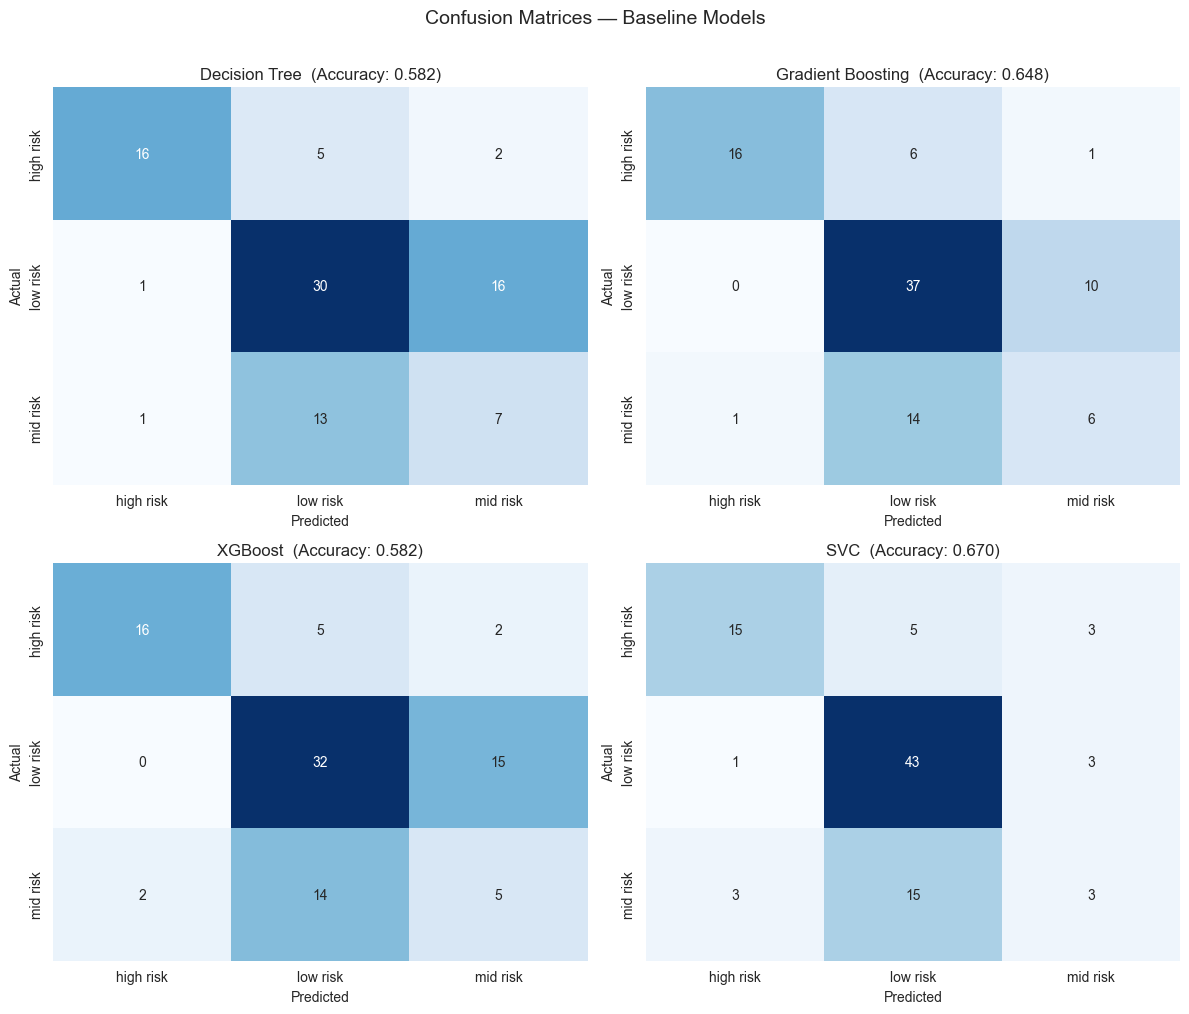

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(f'{name}  (Accuracy: {results[name]["Accuracy"]:.3f})')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('Confusion Matrices — Baseline Models', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

## 6. Model Comparison — Which Model Wins?

Models are ranked by **macro F1**, not accuracy. With ~52% of patients in the `low risk`
class, accuracy is dominated by the majority class — a model can look decent while failing
the patients that matter most. Macro F1 averages the three per-class F1 scores *equally*,
so `high risk` (the clinically expensive miss) counts as much as `low risk`. Accuracy and
weighted F1 are shown for reference.

In [15]:
results_df = (pd.DataFrame(results).T
              .sort_values('F1 (macro)', ascending=False)
              .round(4))
results_df

,Accuracy,F1 (macro),F1 (weighted)
Gradient Boosting,0.6484,0.6091,0.6426
Decision Tree,0.5824,0.5721,0.5937
SVC,0.6703,0.5654,0.6305
XGBoost,0.5824,0.5554,0.5882


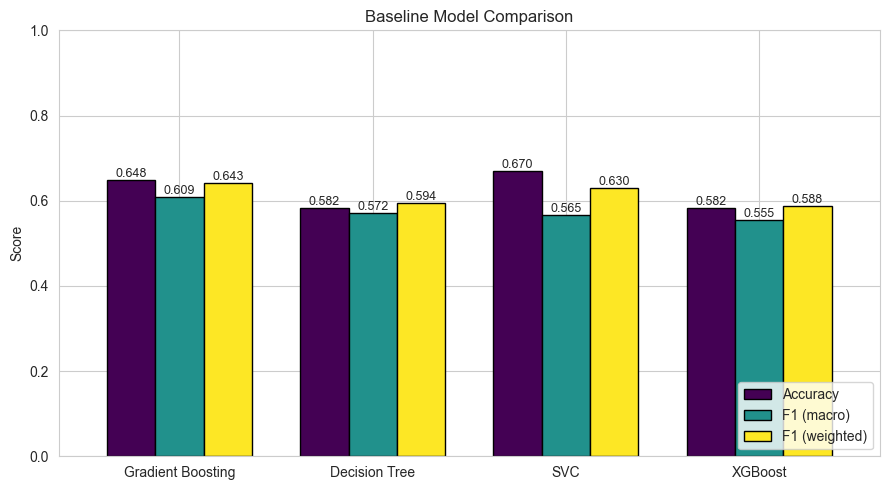

>>> Best baseline model: Gradient Boosting (Macro F1 = 0.6091)


In [16]:
ax = results_df.plot(kind='bar', figsize=(9, 5), rot=0, colormap='viridis',
                     edgecolor='black', width=0.75)
ax.set_title('Baseline Model Comparison')
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=9)
plt.tight_layout()
plt.show()

best_model_name = results_df.index[0]
print(f'>>> Best baseline model: {best_model_name} '
      f'(Macro F1 = {results_df.loc[best_model_name, "F1 (macro)"]:.4f})')

## 7. Hyperparameter Tuning of the Best Model with GridSearchCV

`GridSearchCV` tries **every combination** of the hyperparameters we specify, evaluating each
one with **5-fold cross-validation** on the *training set only*. The test set stays untouched
until the final evaluation.

We define a parameter grid for *each* of the four models, then automatically pick the grid
that matches the winning model — so this notebook keeps working even if a different model
wins on a different dataset.

In [17]:
param_grids = {
    'Decision Tree': {
        'max_depth': [3, 5, 10, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'criterion': ['gini', 'entropy'],
    },
    'Gradient Boosting': {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.05, 0.1, 0.2],
        'max_depth': [3, 5, 7],
    },
    'XGBoost': {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.05, 0.1, 0.2],
        'max_depth': [3, 5, 7],
        'subsample': [0.8, 1.0],
    },
    'SVC': {
        'C': [0.1, 1, 10, 100, 1000],
        'gamma': ['scale', 0.01, 0.1, 1],
        'kernel': ['rbf', 'poly'],
    },
}

# Fresh (unfitted) instances so GridSearchCV starts from scratch
base_models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='mlogloss'),
    'SVC': SVC(random_state=RANDOM_STATE),
}

print(f'Tuning: {best_model_name}')
grid_search = GridSearchCV(
    estimator=base_models[best_model_name],
    param_grid=param_grids[best_model_name],
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
)
grid_search.fit(X_train_scaled, y_train)

print(f'\nBest cross-validation macro F1: {grid_search.best_score_:.4f}')
print('Best hyperparameters:')
for param, value in grid_search.best_params_.items():
    print(f'  {param}: {value}')

Tuning: Gradient Boosting
Fitting 5 folds for each of 27 candidates, totalling 135 fits



Best cross-validation macro F1: 0.6225
Best hyperparameters:
  learning_rate: 0.05
  max_depth: 3
  n_estimators: 100


### 7.1 Which hyperparameter combinations performed best?
A look at the top 5 combinations from the search — useful for seeing *which components*
of the grid actually mattered.

In [18]:
cv_results = pd.DataFrame(grid_search.cv_results_)
top5 = (cv_results[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
        .sort_values('rank_test_score')
        .head(5)
        .reset_index(drop=True))
top5

,params,mean_test_score,std_test_score,rank_test_score
0,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.622504,0.023528,1
1,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.619257,0.043705,2
2,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.607896,0.038378,3
3,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.596859,0.037879,4
4,"{'learning_rate': 0.2, 'max_depth': 3, 'n_esti...",0.587273,0.025394,5


## 8. Final Evaluation — Tuned Model vs Baseline on the Test Set

> 💡 **Note:** don't be surprised if the tuned test score is only similar to (or even slightly
> below) the baseline. GridSearchCV optimizes the **cross-validation** score on the training
> data; with a small test set (~91 samples here), one or two flipped predictions moves test
> accuracy by ±2%. The cross-validation score is the more statistically reliable estimate of
> the model's true performance — that is exactly why we use it for model selection.

In [19]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)

f1_baseline = results[best_model_name]['F1 (macro)']
f1_tuned = f1_score(y_test, y_pred_tuned, average='macro')
acc_tuned = accuracy_score(y_test, y_pred_tuned)

print(f'{best_model_name} — baseline test macro F1: {f1_baseline:.4f}')
print(f'{best_model_name} — tuned test macro F1:    {f1_tuned:.4f}  '
      f'(accuracy: {acc_tuned:.4f})')
print(f'Improvement: {f1_tuned - f1_baseline:+.4f}')
print()
print(classification_report(y_test, y_pred_tuned, target_names=le.classes_))

Gradient Boosting — baseline test macro F1: 0.6091
Gradient Boosting — tuned test macro F1:    0.5954  (accuracy: 0.6923)
Improvement: -0.0137

              precision    recall  f1-score   support

   high risk       0.94      0.70      0.80        23
    low risk       0.66      0.94      0.77        47
    mid risk       0.43      0.14      0.21        21

    accuracy                           0.69        91
   macro avg       0.68      0.59      0.60        91
weighted avg       0.68      0.69      0.65        91



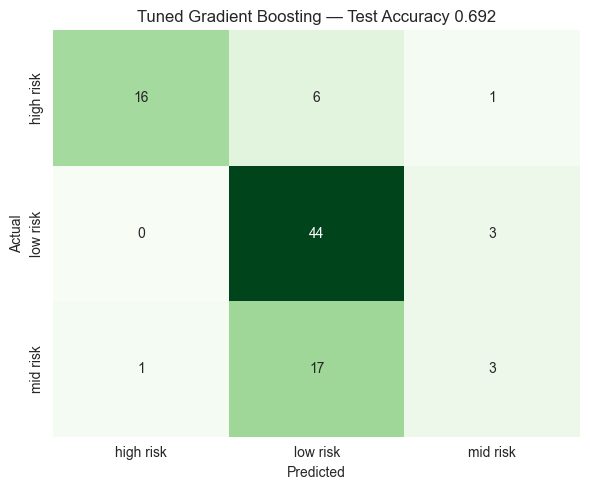

In [20]:
cm = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Tuned {best_model_name} — Test Accuracy {acc_tuned:.3f}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 9. Save the Model with joblib — One Pipeline, One Artifact

For deployment we refit the tuned model inside a single **`Pipeline`**
(`StandardScaler` → model), trained on the **text labels** directly. The saved artifact:

- takes **raw, unscaled** measurements,
- scales them internally with the training-set statistics, and
- returns the answer as text (`'low risk'` / `'mid risk'` / `'high risk'`).

No separate scaler file, no label encoder, no `inverse_transform` — one `joblib.load`,
one `.predict()` call. That is all a serving layer (LLM + Gradio) needs.

> The `LabelEncoder` earlier in the notebook is still required for *training* XGBoost,
> which insists on numeric classes. But sklearn models accept string targets, so the
> final pipeline can be trained to speak text natively. Refitting with the same
> hyperparameters, data and seed reproduces the tuned model exactly — the sanity
> check below proves it.

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Refit the tuned model (same hyperparameters) inside one pipeline, on text labels
final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', clone(grid_search.best_estimator_)),
])
final_pipeline.fit(X_train, le.inverse_transform(y_train))

# Sanity check: identical predictions to the tuned model, now as text
assert (final_pipeline.predict(X_test) == le.inverse_transform(y_pred_tuned)).all()

joblib.dump(final_pipeline, 'maternal_risk_pipeline.joblib')
print('Saved: maternal_risk_pipeline.joblib  (scaler + tuned model, predicts text labels)')

Saved: maternal_risk_pipeline.joblib  (scaler + tuned model, predicts text labels)


### 9.1 Load the Saved Pipeline and Predict a New Patient
Production usage in full: **one load, one predict** — raw measurements in, text label out.

In [22]:
predictor = joblib.load('maternal_risk_pipeline.joblib')

# A new, unseen patient: Age, SystolicBP, DiastolicBP, BS, BodyTemp, HeartRate
new_patient = pd.DataFrame(
    [[35, 140, 95, 13.0, 98, 82]], columns=features)

pred_label = predictor.predict(new_patient)[0]   # scaling happens inside the pipeline

print('New patient data:')
print(new_patient.to_string(index=False))
print(f'\nPredicted risk level: {pred_label.upper()}')

New patient data:
 Age  SystolicBP  DiastolicBP   BS  BodyTemp  HeartRate
  35         140           95 13.0        98         82

Predicted risk level: HIGH RISK


## 10. Conclusion

- We compared **four classifiers** (Decision Tree, Gradient Boosting, XGBoost, SVC) on the
  Maternal Health Risk dataset using a clean, leakage-free workflow: **562 duplicate rows
  removed**, stratified split, and scaling fitted on the training data only.
- **The selection metric mattered.** SVC posted the highest *accuracy* (0.670) but only
  0.565 *macro F1* — it coasts on the 52% `low risk` majority while missing most `mid risk`
  patients. Ranked by **macro F1**, which weights all three classes equally, **Gradient
  Boosting** wins (0.609). With imbalanced classes, the choice of metric literally changes
  which model is "best".
- **GridSearchCV** (scoring = macro F1) chose a conservative Gradient Boosting
  (`learning_rate=0.05`, `max_depth=3`, `n_estimators=100`) with a cross-validation macro F1
  of ~0.62. On the test set the tuned model reaches **0.94 precision / 0.70 recall on
  `high risk`**; `mid risk` remains the hardest class — its symptoms overlap both neighbours.
- The deployment artifact is a **single Pipeline** (`StandardScaler` → tuned model) trained
  on the text labels: one `joblib.load`, one `.predict(raw_measurements)`, and it answers
  `'low risk'` / `'mid risk'` / `'high risk'` directly — no separate scaler, no label
  encoder, no inverse transform. Ready to sit behind an LLM + Gradio front end.

**Possible extensions:** try `RandomizedSearchCV` for larger grids, inspect
`feature_importances_` to explain predictions, or expose `predict_proba` so the serving
layer can phrase its confidence.